In [1]:
from find_obs_overlap import *

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
from astropy.units import u
from astropy.time import Time

In [4]:
from astropy.io import ascii
from astropy.table import Table

In [5]:
import numpy as np

In [6]:
log_folder="../../logs/solar_spectra_logs/"

In [7]:
neid_dates0=ascii.read(log_folder+'neid_dates.csv')

In [8]:
neid_events=[]
for t in neid_dates0['bjd'].value:
    neid_events.append({'midpoint':Time(t,format='jd'),'duration':55})

In [9]:


def read_solar_ccf_for_merge(filename: str) -> Table:
    """
    Read solar CCF file using astropy.ascii and prepare it for merge_events_astropy.
    
    Applies:
      - quality filter (quality >= 0.90)
      - drop rows with missing ccf_mnvel
      - convert `tobs` to astropy Time
      - keep `exptime` as duration in seconds

    Returns:
      Astropy Table suitable for merge_events_astropy
    """

    # Read with astropy.ascii
    tab = ascii.read(filename)

    # Ensure expected column names exist
    expected_cols = {"obs_id", "tobs", "doy", "airmass", "quality",
                     "exptime", "ccf_mnvel", "ccf_errvel"}
    missing = expected_cols - set(tab.colnames)
    if missing:
        raise ValueError(f"Missing expected columns: {missing}")

    # Convert tobs → astropy Time
    tab["tobs"] = Time(tab["tobs"])

    # Convert ccf_mnvel to float & filter out missing values
    # astropy.ascii may bring missing values as masked entries
    if np.ma.isMaskedArray(tab["ccf_mnvel"]):
        valid_mnvel = ~tab["ccf_mnvel"].mask
    else:
        valid_mnvel = ~np.isnan(tab["ccf_mnvel"].astype(float))

    # Quality filter
    good_quality = tab["quality"] >= -0.90

    # Combined mask
    good = good_quality & valid_mnvel

    tab = tab[good]

    # Return clean table ready for merge_events_astropy
    return tab


In [10]:
ex_dates0=read_solar_ccf_for_merge(log_folder+'solar_ccf_210101_250912.csv')

In [11]:
ex_dates0

obs_id,tobs,doy,airmass,quality,exptime,ccf_mnvel,ccf_errvel
float64,Time,int64,float64,float64,int64,float64,float64
210102.1064,2021-01-02 15:52:41.195,210102,4.5133276,0.93269324,600,-634.8426953125,13.827950439453126
210102.1066,2021-01-02 16:15:19.845,210102,3.612422,-0.11316585,600,-674.3784375,1.7523599243164063
210102.1071,2021-01-02 16:49:10.780,210102,2.7977808,0.9092666,331,-647.39734375,0.1768199920654297
210102.1074,2021-01-02 16:58:18.575,210102,2.6656618,0.7330753,382,-644.274609375,0.17628999710083007
210102.1075,2021-01-02 17:04:20.035,210102,2.5760849,0.99070585,290,-649.380625,0.17690000534057618
210102.1082,2021-01-02 17:33:24.351,210102,2.2719476,0.99134624,277,-649.33890625,0.17729999542236327
210102.1087,2021-01-02 17:59:33.208,210102,2.0927696,0.9916659,266,-649.88671875,0.17680999755859375
210102.1092,2021-01-02 18:17:03.730,210102,2.0079696,0.99011713,263,-648.681796875,0.17722999572753906
210102.1093,2021-01-02 18:22:03.727,210102,1.988011,0.9917402,262,-649.0240625,0.1768199920654297


In [12]:
ex_events=[]
for t,d in zip(ex_dates0['tobs'].value,ex_dates0['exptime'].value):
    ex_events.append({'midpoint':Time(t),'duration':d})

In [13]:
neid_blocks=merge_events_astropy(neid_events)

In [14]:
ex_blocks=merge_events_astropy(ex_events)

In [15]:
overlaps= block_overlaps_astropy(neid_blocks,ex_blocks,min_overlap_minutes=110)

In [16]:
overlap_durs=[(item[1]-item[0]).value for item in overlaps]

In [17]:
len(overlap_durs)

363

In [18]:
overlap_starts=[item[0].jd for item in overlaps]

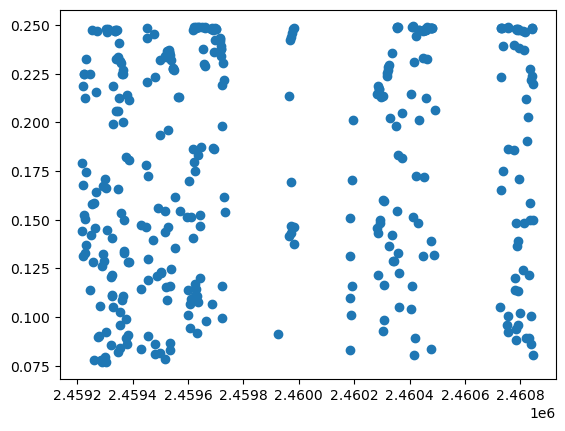

In [19]:
plt.scatter(overlap_starts,overlap_durs)

In [20]:
np.floor(overlap_durs/np.min(overlap_durs))

array([1., 2., 2., 1., 2., 1., 2., 2., 2., 1., 1., 3., 2., 1., 2., 1., 1.,
       3., 2., 1., 1., 2., 1., 2., 2., 3., 1., 1., 1., 1., 1., 1., 1., 2.,
       1., 1., 2., 1., 1., 2., 3., 1., 3., 3., 1., 1., 1., 1., 1., 1., 2.,
       2., 1., 3., 3., 3., 3., 3., 2., 3., 3., 2., 2., 1., 2., 3., 1., 1.,
       3., 1., 1., 3., 1., 2., 2., 2., 2., 1., 1., 1., 1., 1., 1., 2., 2.,
       1., 1., 1., 1., 2., 2., 1., 1., 1., 1., 2., 3., 3., 2., 1., 1., 1.,
       2., 1., 3., 2., 1., 1., 1., 2., 1., 3., 2., 1., 1., 2., 1., 1., 3.,
       3., 1., 3., 1., 3., 2., 1., 3., 3., 3., 3., 3., 1., 1., 1., 3., 1.,
       2., 2., 2., 2., 1., 2., 2., 2., 2., 1., 1., 1., 2., 1., 1., 1., 1.,
       2., 3., 1., 3., 2., 1., 1., 3., 2., 1., 3., 3., 1., 1., 1., 2., 3.,
       3., 1., 1., 1., 2., 3., 3., 3., 3., 2., 3., 1., 3., 1., 3., 3., 2.,
       2., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 1., 1., 2., 2.,
       3., 2., 2., 2., 1., 1., 2., 3., 1., 3., 2., 1., 3., 3., 1., 3., 1.,
       1., 1., 1., 1., 1.

In [21]:
np.sum(np.floor(overlap_durs/np.min(overlap_durs)))

683.0

In [22]:
np.min(overlap_durs)

0.07665334522022138

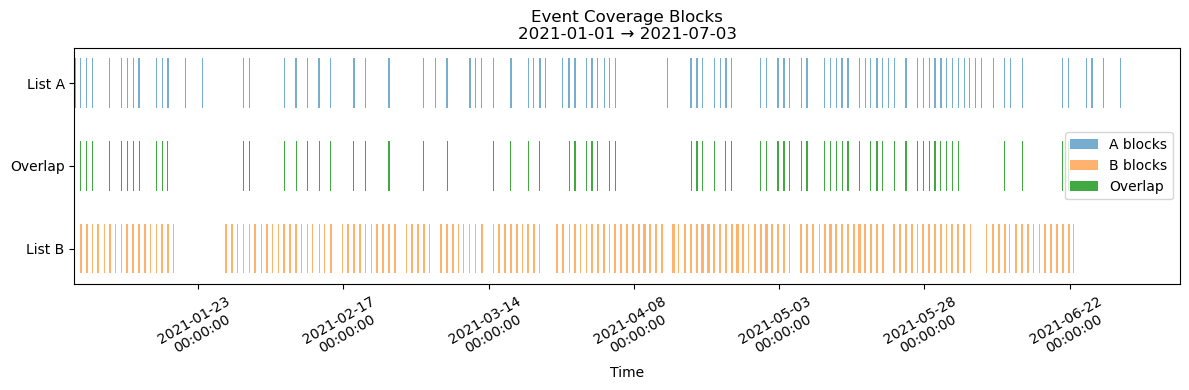

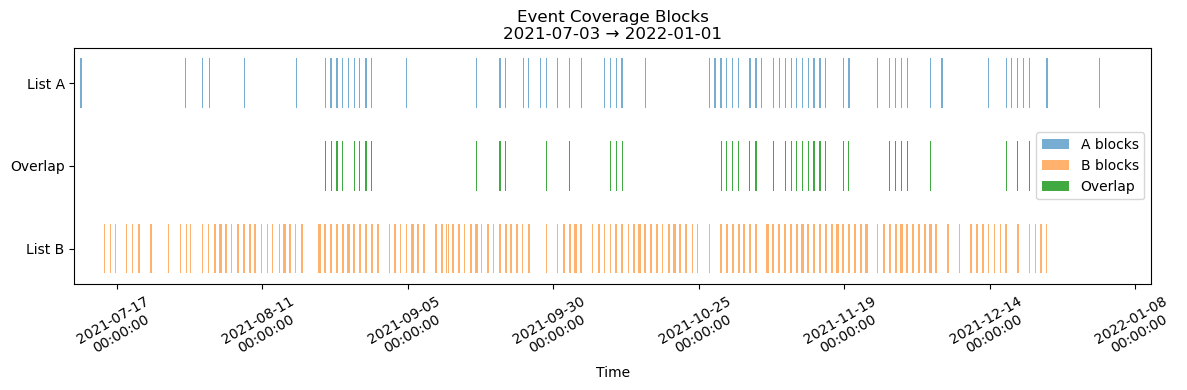

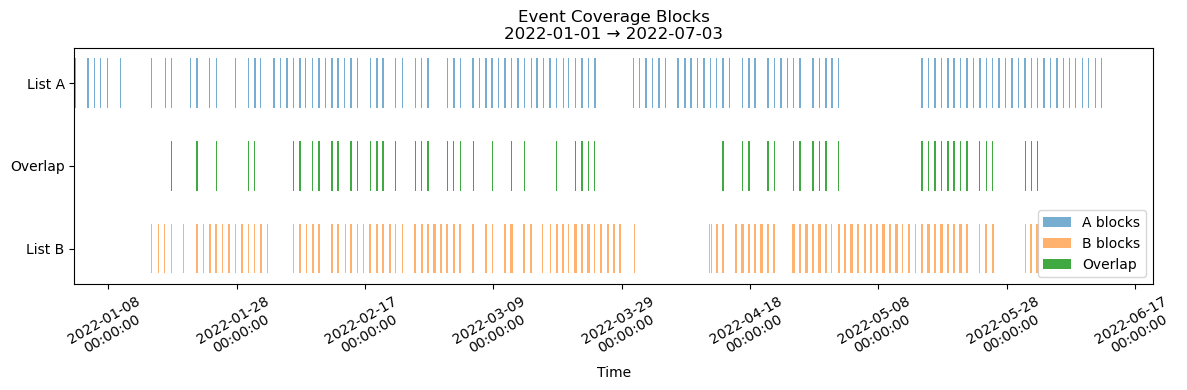

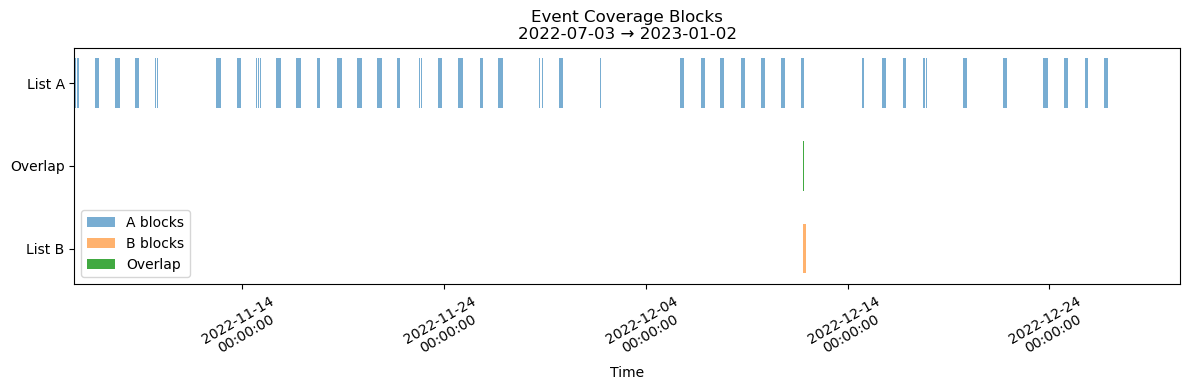

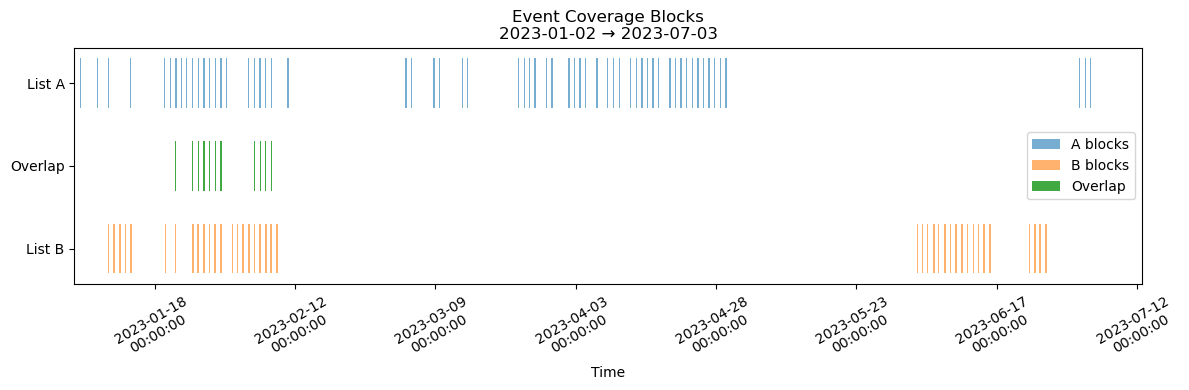

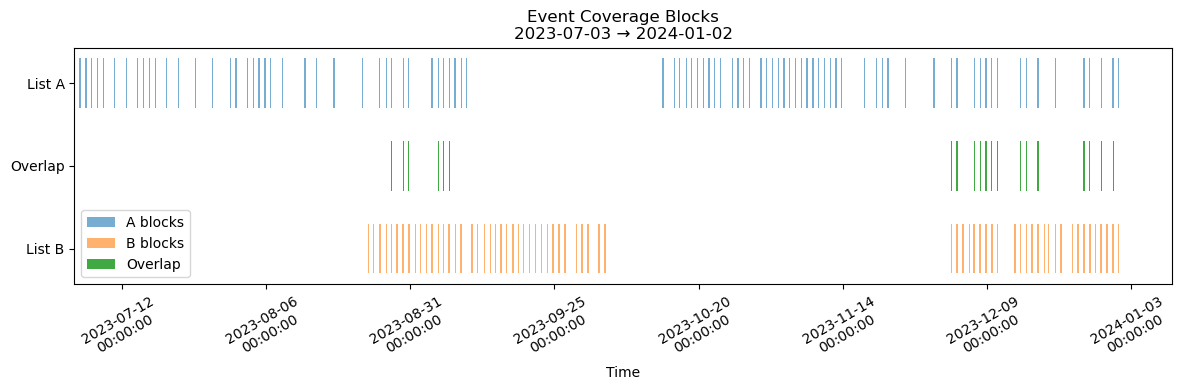

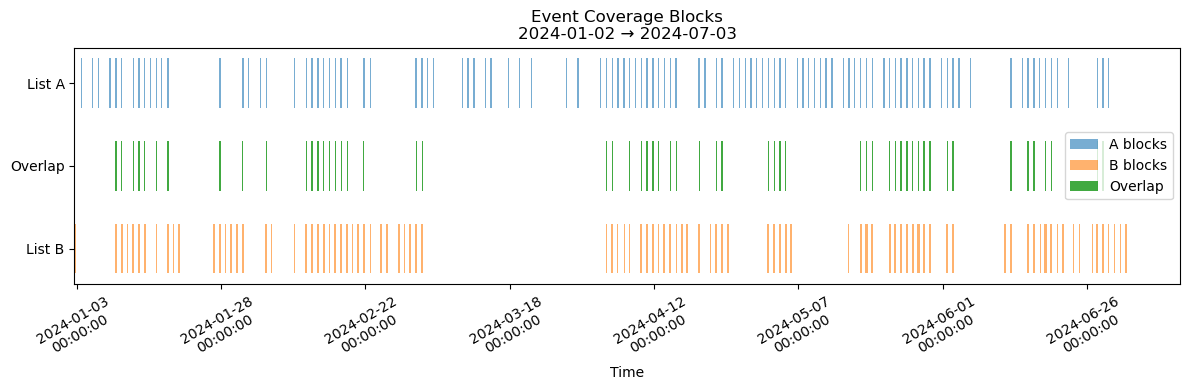

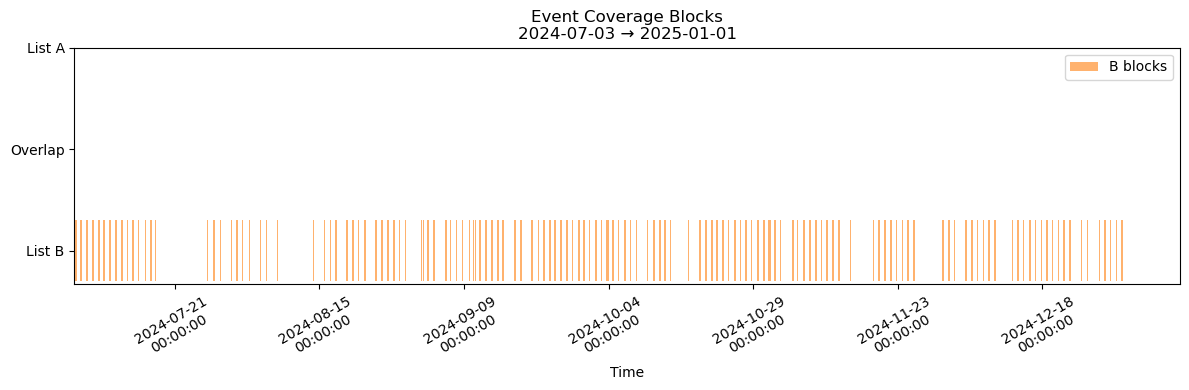

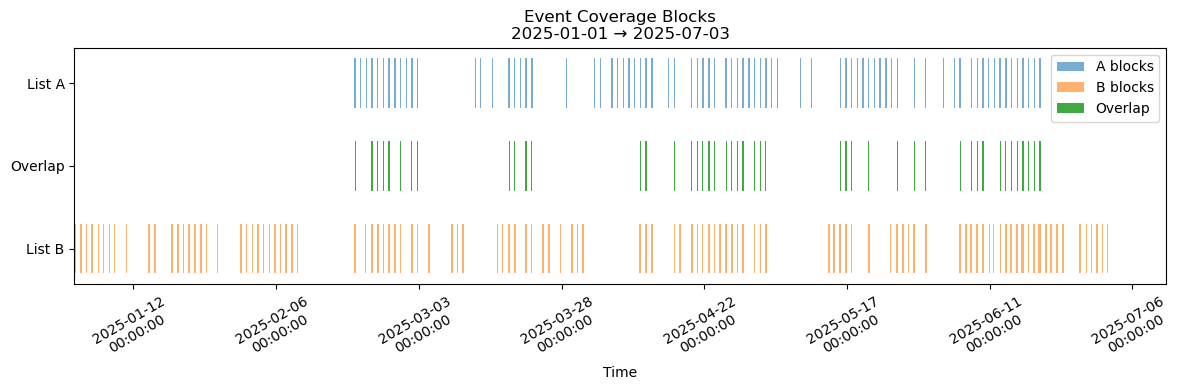

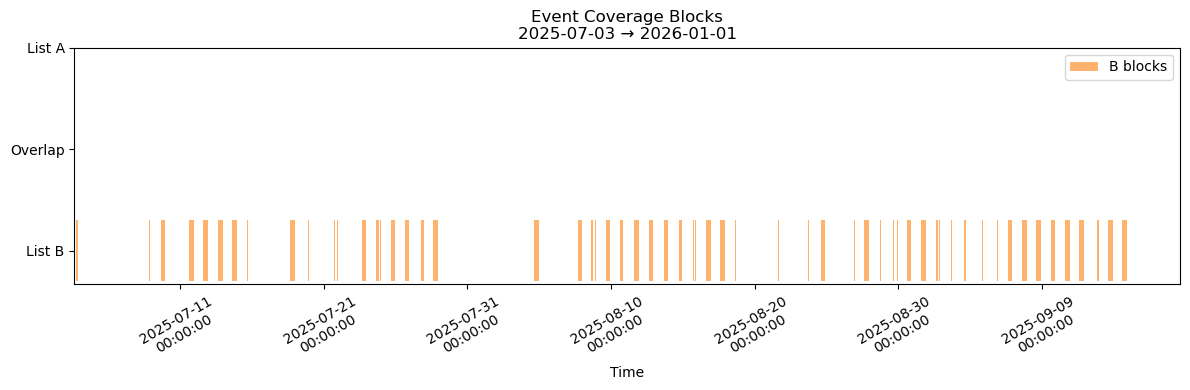

In [23]:
plot_blocks(neid_blocks, ex_blocks, overlaps)

In [24]:
len(overlaps)

363

In [26]:
overlaps

[(<Time object: scale='utc' format='mjd' value=59216.704114003944>,
  <Time object: scale='utc' format='mjd' value=59216.84851505803>),
 (<Time object: scale='utc' format='mjd' value=59217.74210575232>,
  <Time object: scale='utc' format='mjd' value=59217.921412801>),
 (<Time object: scale='utc' format='mjd' value=59218.70438517295>,
  <Time object: scale='utc' format='mjd' value=59218.92301118104>),
 (<Time object: scale='utc' format='mjd' value=59219.70400971118>,
  <Time object: scale='utc' format='mjd' value=59219.83519859901>),
 (<Time object: scale='utc' format='mjd' value=59220.703985880034>,
  <Time object: scale='utc' format='mjd' value=59220.871597014>),
 (<Time object: scale='utc' format='mjd' value=59221.703036643936>,
  <Time object: scale='utc' format='mjd' value=59221.85541739604>),
 (<Time object: scale='utc' format='mjd' value=59223.7031426969>,
  <Time object: scale='utc' format='mjd' value=59223.927897684836>),
 (<Time object: scale='utc' format='mjd' value=59224.703

In [30]:
#convert overlaps to a list of tuples in MJD format
overlaps1=[]
for item in overlaps:
    overlaps1.append( (item[0].jd, item[1].jd) )

In [31]:
overlaps1

[(2459217.204114004, 2459217.348515058),
 (2459218.242105752, 2459218.421412801),
 (2459219.204385173, 2459219.423011181),
 (2459220.2040097113, 2459220.335198599),
 (2459221.20398588, 2459221.371597014),
 (2459222.203036644, 2459222.355417396),
 (2459224.203142697, 2459224.4278976847),
 (2459225.203034051, 2459225.428061504),
 (2459226.2163541783, 2459226.429106042),
 (2459227.2800558913, 2459227.4305163887),
 (2459229.299176956, 2459229.431964051),
 (2459230.200278808, 2459230.433037558),
 (2459231.199920162, 2459231.374276123),
 (2459232.200731516, 2459232.3375063078),
 (2459245.211744387, 2459245.436911956),
 (2459246.277115174, 2459246.391053345),
 (2459250.2946089352, 2459250.4368157517),
 (2459252.18935941, 2459252.436888518),
 (2459254.279114815, 2459254.437200416),
 (2459256.189123183, 2459256.317476018),
 (2459258.317894711, 2459258.3955810415),
 (2459260.189115729, 2459260.347763113),
 (2459264.188888102, 2459264.334493287),
 (2459266.189120914, 2459266.404621829),
 (2459268

In [34]:
#save overlaps1 to a csv file
ascii.write(Table(rows=overlaps1, names=['start_jd', 'end_jd']), 'window_overlaps.csv', overwrite=True, delimiter=',')